# 08 로컬 VLM – kanana·Phi-4 실행 기록 (10/22)

- `08_local_vlm.ipynb`에서 옮긴 셀이다. 출력은 실행 당시 그대로다.
- 다시 실행하지 않는다. 실행에 쓴 conda 환경 `vlm4x`와 myenv의 실험용 패키지(timm, omegaconf, backoff, soundfile, einops)를 10/22에 지웠고, 이 셀들은 08 노트북의 변수(설정, 지시문, 생성 코드)가 있어야 돈다.
- 결과 데이터: `outputs/local_vlm/local_vlm_records.csv`(기능 B), `local_vlm_records_v2.csv`(규칙 적용 A2)
- 다시 재현할 때의 환경 (Phi-4 모델 카드 requirements 버전, kanana 모델 카드 설치 목록 + einops)

```powershell
conda create -n vlm4x python=3.10 -y
conda run -n vlm4x python -m pip install torch==2.6.0 torchvision==0.21.0 --index-url https://download.pytorch.org/whl/cu124
conda run -n vlm4x python -m pip install transformers==4.48.2 accelerate==1.3.0 peft==0.13.2 soundfile==0.13.1 pillow==11.1.0 scipy==1.15.2 backoff==2.2.1 timm omegaconf einops
```

In [8]:
# kanana 모델 코드(trust_remote_code)가 요구하는 패키지 (첫 실행 로드 오류: "requires ... einops")
%pip install einops

Note: you may need to restart the kernel to use updated packages.


## kanana·Phi-4 재시도 (10/22, 비교 실험 전용)

두 모델은 transformers 공통 코드로 로드되지 않아(위 기록: kanana `Unrecognized configuration class`, Phi-4 `custom code which must be executed`) 모델 저장소의 전용 코드로 돌린다. 이 전용 코드는 비교 실험에만 쓰고, 서비스 코드에는 넣지 않는다(최종 모델이 공통 코드 모델일 때). 두 모델 중 하나가 최종으로 뽑히면 서비스에는 공통 함수(`load_vlm`, `generate`) 안에서만 전용 로드를 나눈다.

- kanana: 모델 카드 Quickstart 방식
  - `AutoModelForVision2Seq` + `trust_remote_code=True`. 설치된 transformers 5.20.1에서 이 자동 클래스 이름이 없을 수 있어, 저장소 설정의 `auto_map`에 적힌 클래스를 직접 불러온다(`get_class_from_dynamic_module`).
  - 입력: `{"image": [이미지], "conv": [{"role": "user", "content": "<image>"}, {"role": "user", "content": 질문}]}`를 `processor.batch_encode_collate(batch, padding_side="left", add_generation_prompt=True, max_length=8192)`로 변환
  - 생성: `do_sample=False`, `num_beams=1` (모델 카드 생성 설정과 같음)
  - 모델 카드 설치 목록: `transformers accelerate timm omegaconf`. 첫 실행 오류로 `einops`도 필요했다.
- Phi-4-multimodal: 위 "생성 및 측정 (규칙 적용)"의 모델 카드 방식 그대로. 두 번째 실행 오류(`requires ... backoff`)에 따라 모델 카드 requirements 중 빠진 `backoff`, `soundfile`, `scipy`를 설치한다(flash_attn은 Windows 미설치라 제외, eager 사용).
- 과제: 규칙 적용 A2 30건(`local_vlm_records_v2.csv`)과 기능 B 6건(`local_vlm_records.csv`). 실행 후 위 "지표 계산"과 "지표 계산 (규칙 적용 전·후)" 셀을 다시 실행하면 표·그래프에 함께 나온다.

In [14]:
# kanana 모델 카드 설치 목록(timm, omegaconf) + Phi-4 모델 카드 requirements 중 빠진 패키지(backoff, soundfile, scipy). 비교 실험 전용
%pip install timm omegaconf backoff soundfile scipy

Note: you may need to restart the kernel to use updated packages.


In [15]:
CHILD_V3 = CHILD_V2.replace(
    """    if a['loader'] == 'phi4_remote':
        from transformers import AutoModelForCausalLM, GenerationConfig""",
    """    if a['loader'] == 'kanana_remote':
        from transformers import AutoConfig
        from transformers.dynamic_module_utils import get_class_from_dynamic_module
        # 모델 카드는 AutoModelForVision2Seq를 쓰지만 transformers 5.x에 이 이름이 없을 수 있어 auto_map의 클래스를 직접 불러옴
        cfg = AutoConfig.from_pretrained(a['repo'], trust_remote_code=True)
        ref = cfg.auto_map.get('AutoModelForVision2Seq') or cfg.auto_map.get('AutoModelForImageTextToText') or cfg.auto_map.get('AutoModelForCausalLM')
        cls = get_class_from_dynamic_module(ref, a['repo'])
        model = cls.from_pretrained(a['repo'], dtype=torch.bfloat16, device_map='cuda')
    elif a['loader'] == 'phi4_remote':
        from transformers import AutoModelForCausalLM, GenerationConfig""").replace(
    """        if a['loader'] == 'phi4_remote':
            # 모델 카드 프롬프트 형식""",
    """        if a['loader'] == 'kanana_remote':
            # 모델 카드 Quickstart 입력 형식 (지시문은 사용자 메시지에 합침)
            conv = ([{'role': 'user', 'content': '<image>'}] if t['image'] else []) + \\
                   [{'role': 'user', 'content': t['system'] + '\\n\\n' + t['prompt']}]
            batch = [{'image': [Image.open(t['image']).convert('RGB')] if t['image'] else [], 'conv': conv}]
            enc = proc.batch_encode_collate(batch, padding_side='left', add_generation_prompt=True, max_length=8192)
            enc = {k: v.to(model.device) if isinstance(v, torch.Tensor) else v for k, v in enc.items()}
            torch.cuda.reset_peak_memory_stats()
            t1 = time.perf_counter()
            with torch.no_grad():
                out = model.generate(**enc, max_new_tokens=a['max_new_tokens'], do_sample=False, num_beams=1)
            rec['sec'] = round(time.perf_counter() - t1, 2)
            n_in = enc['input_ids'].shape[1] if 'input_ids' in enc else 0
            # 출력에 입력 토큰이 앞에 붙어 있으면 잘라냄 (모델 카드는 출력 전체를 디코딩)
            if n_in and out.shape[1] > n_in and torch.equal(out[:, :n_in].cpu(), enc['input_ids'][:, :n_in].cpu()):
                out = out[:, n_in:]
            rec['in_tokens'], rec['out_tokens'] = int(n_in), int(out.shape[1])
            rec['peak_vram_gb'] = round(torch.cuda.max_memory_allocated() / 1024**3, 2)
            rec['text'] = proc.tokenizer.batch_decode(out, skip_special_tokens=True)[0]
            write(rec)
            print(t['task'], t['item'], rec.get('sec'), 's', flush=True)
            continue
        if a['loader'] == 'phi4_remote':
            # 모델 카드 프롬프트 형식""")
assert CHILD_V3.count('kanana_remote') == 2, '자식 프로세스 코드 치환 실패'

RETRY = {
    'kanana_3b': dict(repo='kakaocorp/kanana-1.5-v-3b-instruct', loader='kanana_remote', trust_remote_code=True),
    'phi4_mm': dict(repo='microsoft/Phi-4-multimodal-instruct', loader='phi4_remote', trust_remote_code=True),
}
B_TASKS = [t for t in TASKS if t['task'] == 'B']
for name, m in RETRY.items():
    # kanana·Phi-4는 transformers 5.x(myenv)에서 로드되지 않아 맨 뒤 "transformers 4.48.2 별도 환경" 섹션에서 vlm4x로 돌림
    if name in ('kanana_3b', 'phi4_mm'):
        print(name, 'vlm4x 섹션에서 실행 → 건너뜀')
        continue
    for tasks, out_csv, done_fn in [(TASKS_V2, RECORDS_V2, done_v2), (B_TASKS, RECORDS_CSV, done_items)]:
        todo = [t for t in tasks if t['item'] not in done_fn(name)]
        if not todo:
            print(name, out_csv.name, '이미 완료 → 건너뜀')
            continue
        arg = json.dumps(dict(name=name, repo=m['repo'], loader=m['loader'], trust_remote_code=True,
                              max_new_tokens=MAX_NEW_TOKENS, out=str(out_csv.resolve()), tasks=todo))
        p = subprocess.run([sys.executable, '-c', CHILD_V3], input=arg, capture_output=True, text=True, encoding='utf-8',
                           errors='replace', env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
        print(name, out_csv.name, '\n', p.stdout[-1500:])
        if p.returncode != 0:
            print(p.stderr[-2000:])
        if 'LOAD_FAIL' in p.stdout:
            break

kanana_3b vlm4x 섹션에서 실행 → 건너뜀
phi4_mm vlm4x 섹션에서 실행 → 건너뜀


## kanana·Phi-4 재시도 – transformers 4.48.2 별도 환경 (10/22, 비교 실험 전용)

- 위 재시도는 두 모델 모두 transformers 5.20.1과 맞지 않아 실패했다(kanana `ImportError: cannot import name 'VisionRotaryEmbedding'`, Phi-4 `RuntimeError: Tensor.item() cannot be called on meta tensors`).
- 그래서 두 모델만 Phi-4 모델 카드 requirements 버전(transformers 4.48.2, torch 2.6.0 등)으로 만든 별도 conda 환경 `vlm4x`의 파이썬으로 돌린다. 노트북 커널(myenv)은 그대로다.
- 바뀌는 것은 두 가지다.
  - 자식 프로세스를 `vlm4x`의 python.exe로 실행
  - transformers 4.x는 정밀도 인자 이름이 `torch_dtype`이라 자식 코드의 `dtype=`을 `torch_dtype=`으로 바꿈
- 모델 파일은 같은 HF 캐시를 쓰므로 다시 받지 않는다. 결과는 같은 CSV에 저장되고, 이 섹션의 "지표·그래프 다시 계산" 셀이 두 모델을 포함해 표·그래프를 다시 그린다.
- 앞의 "생성 및 측정", "생성 및 측정 (규칙 적용)", "kanana·Phi-4 재시도 (10/22, 비교 실험 전용)" 셀은 두 모델을 건너뛰게 고쳤다(myenv에서는 로드 실패). 전체 실행 한 번으로 두 모델 실험까지 돈다.

In [16]:
# vlm4x 환경 확인: 2.6.0+cu124 True 4.48.2 가 나와야 함
ENV4X_PY = Path(r'C:\Users\Administrator\miniconda3\envs\vlm4x\python.exe')
assert ENV4X_PY.exists(), f'{ENV4X_PY} 없음 → PowerShell에서 conda env list로 경로 확인'
ENV4X = {**os.environ, 'PYTHONIOENCODING': 'utf-8',
         # myenv 경로가 PATH 앞에 있으면 다른 환경의 DLL을 먼저 찾을 수 있어 vlm4x 경로를 앞에 둠
         'PATH': os.pathsep.join([str(ENV4X_PY.parent), str(ENV4X_PY.parent / 'Library' / 'bin'),
                                  str(ENV4X_PY.parent / 'Scripts'), os.environ.get('PATH', '')])}
ENV4X.pop('PYTHONPATH', None)
r = subprocess.run([str(ENV4X_PY), '-c', 'import torch, transformers, PIL, peft, timm, einops, omegaconf, backoff, soundfile, scipy; '
                    'print(torch.__version__, torch.cuda.is_available(), transformers.__version__, PIL.__version__, peft.__version__)'],
                   capture_output=True, text=True, encoding='utf-8', errors='replace', env=ENV4X)
print(r.stdout, r.stderr[-1500:])

2.6.0+cu124 True 4.48.2 11.1.0 0.13.2
 


In [17]:
import re

# 이 섹션만 따로 실행할 때도 돌도록, 이전 생성 셀(생성 및 측정, 생성 및 측정 (규칙 적용), kanana·Phi-4 재시도)의
# 정의 부분(첫 'for name, m in' 반복문 앞)만 이 노트북 파일에서 읽어 실행한다
_nb = json.loads((ROOT / 'experiments' / '08_local_vlm.ipynb').read_text(encoding='utf-8'))
for _head in ['CHILD = r"""', 'CHILD_V2 = CHILD.replace(', 'CHILD_V3 = CHILD_V2.replace(']:
    _src = [''.join(c['source']) for c in _nb['cells'] if c['cell_type'] == 'code' and ''.join(c['source']).startswith(_head)]
    assert len(_src) == 1, f'{_head} 셀 {len(_src)}개'
    exec(_src[0][:_src[0].index('\nfor name, m in')])

CHILD_V4, n_sub = re.subn(r'(?<!torch_)dtype=torch\.bfloat16', 'torch_dtype=torch.bfloat16', CHILD_V3)
assert n_sub == 3, f'dtype 치환 {n_sub}곳 (3곳이어야 함)'

for name, m in RETRY.items():
    for tasks, out_csv, done_fn in [(TASKS_V2, RECORDS_V2, done_v2), (B_TASKS, RECORDS_CSV, done_items)]:
        todo = [t for t in tasks if t['item'] not in done_fn(name)]
        if not todo:
            print(name, out_csv.name, '이미 완료 → 건너뜀')
            continue
        arg = json.dumps(dict(name=name, repo=m['repo'], loader=m['loader'], trust_remote_code=True,
                              max_new_tokens=MAX_NEW_TOKENS, out=str(out_csv.resolve()), tasks=todo))
        p = subprocess.run([str(ENV4X_PY), '-c', CHILD_V4], input=arg, capture_output=True, text=True, encoding='utf-8',
                           errors='replace', env=ENV4X)
        print(name, out_csv.name, '\n', p.stdout[-1500:])
        if p.returncode != 0:
            print(p.stderr[-2000:])
        if 'LOAD_FAIL' in p.stdout:
            break

kanana_3b local_vlm_records_v2.csv 이미 완료 → 건너뜀
kanana_3b local_vlm_records.csv 이미 완료 → 건너뜀
phi4_mm local_vlm_records_v2.csv 이미 완료 → 건너뜀
phi4_mm local_vlm_records.csv 
 LOADED phi4_mm 14.5 s
B B0 6.08 s
B B1 5.98 s
B B2 7.1 s
B B3 7.95 s
B B4 6.74 s
B B5 28.91 s



### 지표·그래프 다시 계산 (kanana·Phi-4 포함)

위 "지표 계산", "시각화", "지표 계산 (규칙 적용 전·후)", "시각화 (규칙 적용 전·후)" 셀을 같은 코드로 다시 실행해, 전체 실행 한 번으로 두 모델 결과가 표·그래프에 들어가게 한다.

로드 실패:


,model,error
0,kanana_3b,ImportError: This modeling file requires the following packages that were not found in your environment: einops. Run `pip install einops`
1,kanana_3b,ImportError: This modeling file requires the following packages that were not found in your environment: einops. Run `pip install einops`
2,phi4_mm,ValueError: The repository microsoft/Phi-4-multimodal-instruct contains custom code which must be executed to correctly load the model. You can inspect the repository content at https://hf.co/microsoft/Phi-4-multimodal-instruct .\n You can inspect the repository content at https://hf.co/microsof...
24,kanana_3b,ImportError: This modeling file requires the following packages that were not found in your environment: einops. Run `pip install einops`
46,phi4_mm,ValueError: The repository microsoft/Phi-4-multimodal-instruct contains custom code which must be executed to correctly load the model. You can inspect the repository content at https://hf.co/microsoft/Phi-4-multimodal-instruct .\n You can inspect the repository content at https://hf.co/microsof...
47,kanana_3b,ValueError: Unrecognized configuration class <class 'transformers_modules.kakaocorp.kanana_hyphen_1_dot_5_hyphen_v_hyphen_3b_hyphen_instruct.2e00ef13ccec2e99459a8eada18a1bfd05bff44b.configuration.KananaVConfig'> for this kind of AutoModel: AutoModelForImageTextToText.\nModel type should be one o...
48,phi4_mm,ValueError: The repository microsoft/Phi-4-multimodal-instruct contains custom code which must be executed to correctly load the model. You can inspect the repository content at https://hf.co/microsoft/Phi-4-multimodal-instruct .\n You can inspect the repository content at https://hf.co/microsof...
49,kanana_3b,ValueError: Unrecognized configuration class <class 'transformers_modules.kakaocorp.kanana_hyphen_1_dot_5_hyphen_v_hyphen_3b_hyphen_instruct.2e00ef13ccec2e99459a8eada18a1bfd05bff44b.configuration.KananaVConfig'> for this kind of AutoModel: AutoModelForImageTextToText.\nModel type should be one o...
50,phi4_mm,ValueError: The repository microsoft/Phi-4-multimodal-instruct contains custom code which must be executed to correctly load the model. You can inspect the repository content at https://hf.co/microsoft/Phi-4-multimodal-instruct .\n You can inspect the repository content at https://hf.co/microsof...
51,kanana_3b,ValueError: Unrecognized configuration class <class 'transformers_modules.kakaocorp.kanana_hyphen_1_dot_5_hyphen_v_hyphen_3b_hyphen_instruct.2e00ef13ccec2e99459a8eada18a1bfd05bff44b.configuration.KananaVConfig'> for this kind of AutoModel: AutoModelForImageTextToText.\nModel type should be one o...


,n,json_ok,format_ok,ko_ratio,sec
model,,,,,
kanana_3b,NaN,NaN,NaN,NaN,NaN
gemma3_4b,15.0,1.0,0.200,0.998,9.681
phi4_mm,NaN,NaN,NaN,NaN,NaN
qwen3vl_8b,15.0,1.0,0.733,0.995,38.166
claude-haiku-5-5,15.0,1.0,0.667,0.996,3.560
claude-sonnet-5-5,15.0,1.0,0.467,0.997,3.155
claude-opus-5-5,15.0,1.0,0.800,0.999,5.729


,n,json_ok,scene_en_ratio,tags_ok,title_ok,numbers_kept,sec
model,,,,,,,
kanana_3b,6,1.000,1.0,1.000,1.000,1.000,3.722
gemma3_4b,6,1.000,1.0,1.000,1.000,0.950,6.780
phi4_mm,6,0.833,1.0,0.833,0.500,0.817,10.460
qwen3vl_8b,6,1.000,1.0,1.000,1.000,1.000,4.430
claude-haiku-5-5,6,1.000,1.0,1.000,0.667,1.000,2.025
claude-sonnet-5-5,6,1.000,1.0,1.000,0.667,1.000,1.873
claude-opus-5-5,6,1.000,1.0,1.000,1.000,1.000,5.605


,load_sec,peak_vram_gb,download_sec,download_gb
model,,,,
kanana_3b,11.5,6.87,0.2,6.85
gemma3_4b,10.3,8.14,97.0,8.05
phi4_mm,14.5,11.24,0.3,11.99
qwen3vl_8b,19.1,16.73,137.6,16.34


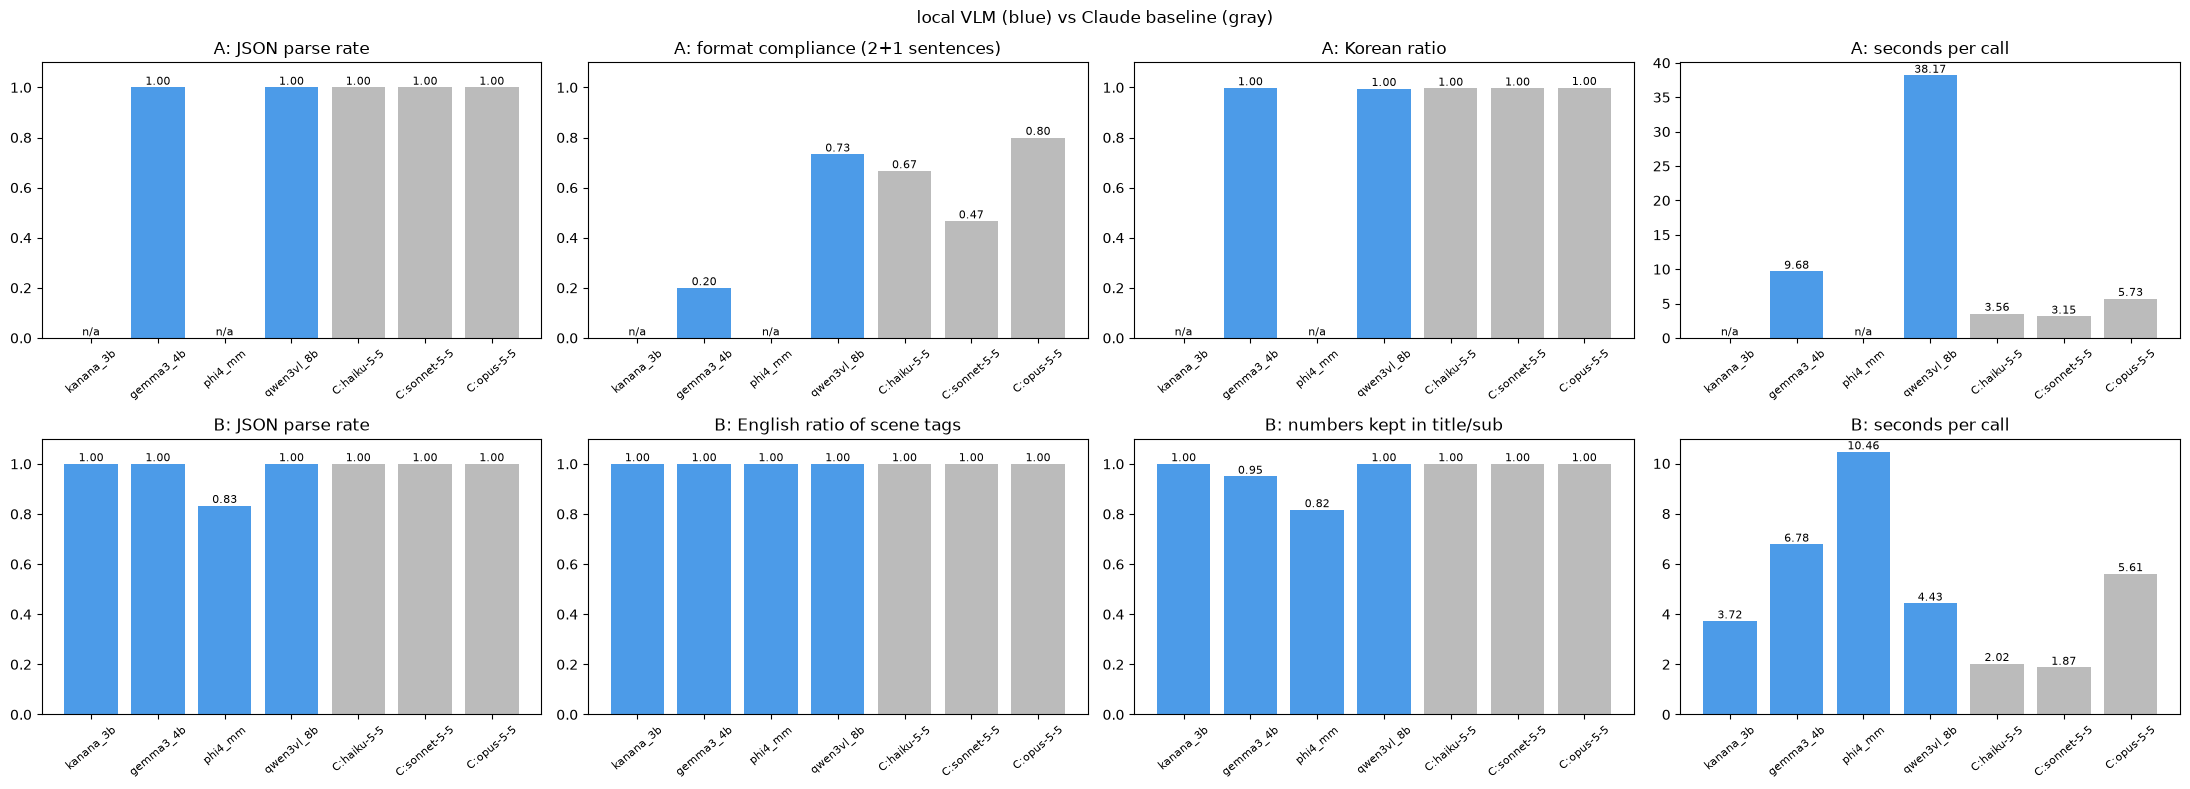

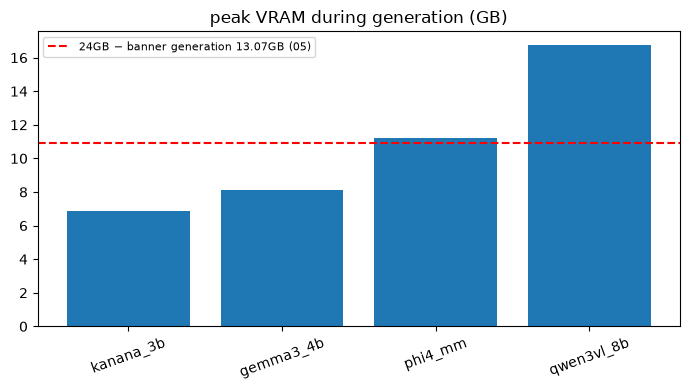

로드 실패 (v2):


,model,error
0,kanana_3b,ValueError: Unrecognized configuration class <class 'transformers_modules.kakaocorp.kanana_hyphen_1_dot_5_hyphen_v_hyphen_3b_hyphen_instruct.2e00ef13ccec2e99459a8eada18a1bfd05bff44b.configuration.KananaVConfig'> for this kind of AutoModel: AutoModelForImageTextToText.\nModel type should be one o...
31,phi4_mm,ImportError: This modeling file requires the following packages that were not found in your environment: backoff. Run `pip install backoff`
62,kanana_3b,ValueError: Unrecognized configuration class <class 'transformers_modules.kakaocorp.kanana_hyphen_1_dot_5_hyphen_v_hyphen_3b_hyphen_instruct.2e00ef13ccec2e99459a8eada18a1bfd05bff44b.configuration.KananaVConfig'> for this kind of AutoModel: AutoModelForImageTextToText.\nModel type should be one o...
63,phi4_mm,RuntimeError: Tensor.item() cannot be called on meta tensors
64,kanana_3b,ImportError: cannot import name 'VisionRotaryEmbedding' from 'transformers.models.qwen2_vl.modeling_qwen2_vl' (c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\transformers\models\qwen2_vl\modeling_qwen2_vl.py)
65,phi4_mm,RuntimeError: Tensor.item() cannot be called on meta tensors
66,kanana_3b,ValueError: Unrecognized configuration class <class 'transformers_modules.kakaocorp.kanana_hyphen_1_dot_5_hyphen_v_hyphen_3b_hyphen_instruct.2e00ef13ccec2e99459a8eada18a1bfd05bff44b.configuration.KananaVConfig'> for this kind of AutoModel: AutoModelForImageTextToText.\nModel type should be one o...
67,phi4_mm,RuntimeError: Tensor.item() cannot be called on meta tensors
68,kanana_3b,ValueError: Unrecognized configuration class <class 'transformers_modules.kakaocorp.kanana_hyphen_1_dot_5_hyphen_v_hyphen_3b_hyphen_instruct.2e00ef13ccec2e99459a8eada18a1bfd05bff44b.configuration.KananaVConfig'> for this kind of AutoModel: AutoModelForImageTextToText.\nModel type should be one o...
69,phi4_mm,RuntimeError: Tensor.item() cannot be called on meta tensors


n  json_ok  format_ok  ko_ratio  \
model             version                                               
claude-haiku-5-5  v1 (before rules)  15    1.000      0.667     0.996   
claude-opus-5-5   v1 (before rules)  15    1.000      0.800     0.999   
claude-sonnet-5-5 v1 (before rules)  15    1.000      0.467     0.997   
gemma3_4b         v1 (before rules)  15    1.000      0.200     0.998   
                  v2 no_input        15    1.000      0.733     0.996   
                  v2 user_input      15    1.000      0.200     1.000   
kanana_3b         v2 no_input        15    1.000      0.000     0.993   
                  v2 user_input      15    1.000      0.000     0.996   
phi4_mm           v2 no_input        15    0.933      0.600     0.781   
                  v2 user_input      15    0.867      0.133     0.993   
qwen3vl_8b        v1 (before rules)  15    1.000      0.733     0.995   
                  v2 no_input        15    1.000      1.000     0.995   
                  v2 user_input      15    1.000      0.267     0.998   

                                     promo_violation  cliche must_kept     sec  
model             version                                                       
claude-haiku-5-5  v1 (before rules)            0.000   0.867       NaN   3.560  
claude-opus-5-5   v1 (before rules)            0.000   1.000       NaN   5.729  
claude-sonnet-5-5 v1 (before rules)            0.000   1.000       NaN   3.155  
gemma3_4b         v1 (before rules)            0.067   0.200       NaN   9.681  
                  v2 no_input                  0.000   0.000       NaN   9.097  
                  v2 user_input                0.000   0.000  0.066667  10.136  
kanana_3b         v2 no_input                  0.000   0.733       NaN  10.535  
                  v2 user_input                0.000   0.733       0.6   9.823  
phi4_mm           v2 no_input                  0.000   0.067       NaN  16.527  
                  v2 user_input                0.000   0.000       0.4  19.815  
qwen3vl_8b        v1 (before rules)            0.000   0.467       NaN  38.166  
                  v2 no_input                  0.000   0.067       NaN   8.533  
                  v2 user_input                0.000   0.000       1.0   8.119

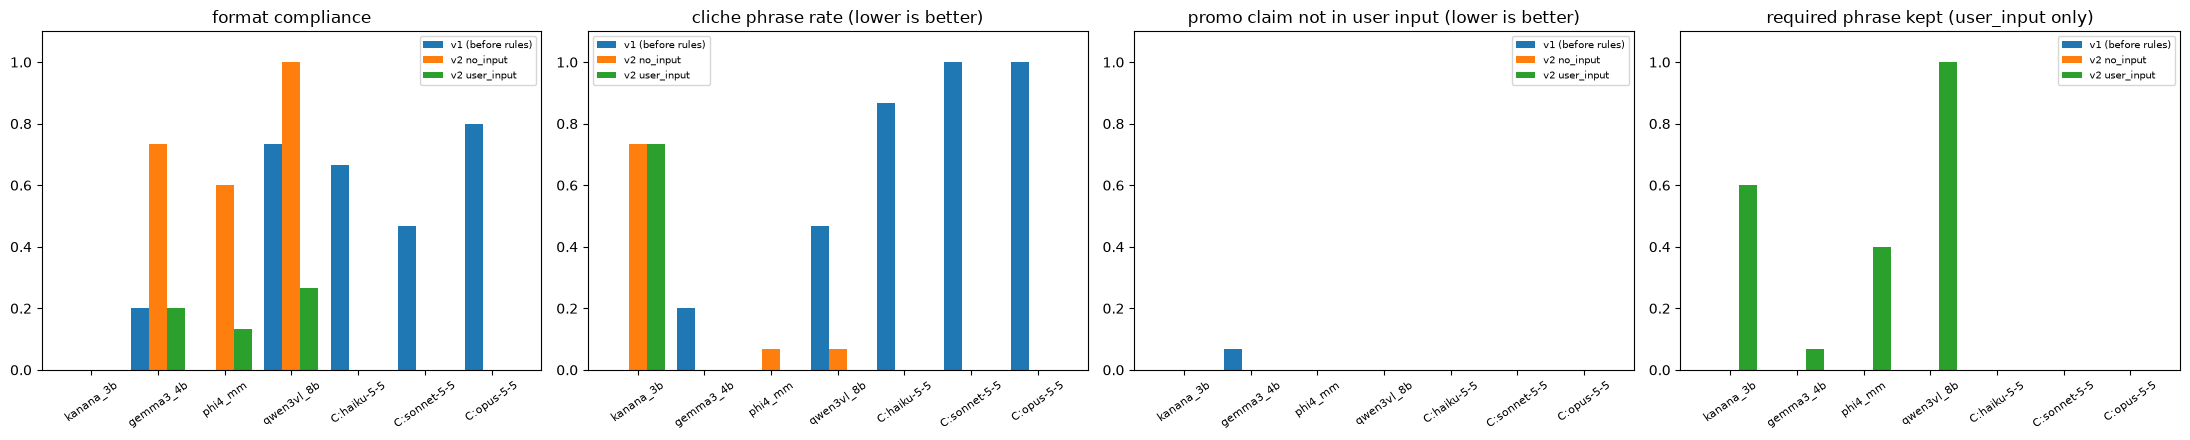

,model,version,cliche,promo_violation,must_kept,text
0,qwen3vl_8b,v1 (before rules),True,False,NaN,"{""store"": [""검은 고양이 기사가 모험을 떠나는 귀여운 2D 어드벤처 게임!"", ""사냥보다는 친구를 사냥하는, 따뜻한 마음의 여정을 경험해보세요.""], ""sns"": ""냥기사의 여행, 고양이 기사가 빛나는 모험을 시작합니다! 🐱""}"
15,gemma3_4b,v1 (before rules),True,False,NaN,"```json\n{\n ""store"": [""귀여운 검은 고양이 기사, 냥기사의 특별한 여행을 시작하세요! 흥미진진한 모험과 깜찍한 요소가 가득한 2D 횡스크롤 어드벤처 게임입니다."", ""친구들과 함께 즐기기에도 딱 좋은, 스트레스 해소에 최고인 게임! 지금 바로 다운로드하고 냥기사의 모험을 함께 떠나세요.""],\n ""sns"": ""귀여운 냥기사, 어디로 떠날까요? 🐾""\n}\n```"
30,claude-haiku-5-5,v1 (before rules),True,False,NaN,"{""store"": [""빨간 모자를 쓴 검은 고양이 기사가 돌담 마을과 초록 들판을 누비는 2D 횡스크롤 모험, 냥기사의 여행이 시작됩니다!"", ""귀여운 토끼 친구들과 마주치며 용감하게 길을 떠나는 고양이 기사와 함께, 따뜻하고 아기자기한 세계를 탐험해 보세요.""], ""sns"": ""빨간 모자 쓴 검은 고양이 기사가 떠나는 모험, 냥기사의 여행과 함께 오늘도 귀여운 모험을 떠나볼까요? 🐾⚔️""}"
31,claude-sonnet-5-5,v1 (before rules),True,False,NaN,"{""store"": [""빨간 모자를 눌러쓴 검은 고양이 기사와 함께 이끼 낀 오래된 성터를 누비며 숨겨진 비밀을 찾아 떠나는 2D 횡스크롤 어드벤처 <냥기사의 여행>입니다."", ""손그림 같은 따뜻한 풍경 속에서 귀여운 토끼 친구들을 만나고 작은 모험을 하나씩 이겨 내며, 포근하고 즐거운 여정을 느껴 보세요.""], ""sns"": ""빨간 모자 쓴 냥기사와 함께 폭신폭신 모험을 떠나요 🐱🎩 <냥기사의 여행>에서 귀여운 친구들이 기다리고 있어요! #냥기사의여행 #인디게임""}"
32,claude-opus-5-5,v1 (before rules),True,False,NaN,"{""store"": [""빨간 모자와 망토를 두른 작은 검은 고양이 기사가 이끼 낀 고성의 폐허 속으로 씩씩하게 모험을 떠납니다!"", ""풀숲에 숨은 새하얀 토끼 친구와 오래된 돌벽 너머의 비밀을 찾아 따뜻하고 귀여운 2D 횡스크롤 여행을 함께 즐겨보세요.""], ""sns"": ""빨간 모자 냥기사가 고성 폐허에서 새하얀 토끼를 만났어요, 이 귀여운 모험에 함께 떠나볼까요? 🐾""}"
75,gemma3_4b,v2 no_input,False,False,NaN,"```json\n{\n ""store"": [""빨간 모자를 쓴 검은 고양이 기사가 칼을 휘두르는 모습이 눈에 띄는 냥기사의 여행."", ""동화 속 풍경을 담은 손그림 스타일과 개 기사, 부엉이 마법사 등 매력적인 동료들이 당신을 기다립니다.""],\n ""sns"": ""숲 속 선술집에서 만난 개 기사와 함께 용감한 모험을 시작하세요!""\n}\n```"
90,gemma3_4b,v2 user_input,False,False,False,"```json\n{\n ""store"": [""빨간 모자를 쓴 검은 고양이 기사가 던진 칼이 빗나가고 있네요! 흥미진진한 횡스크롤 액션 어드벤처 게임, 냥기사의 여행을 지금 바로 만나보세요."", ""동화 속 풍경을 옮겨온 듯한 아름다운 손그림 스테이지와 개 기사, 부엉이 마법사, 토끼 상인 등 다채로운 동료들이 여러분을 기다립니다.""],\n ""sns"": ""11월 업데이트 기념! 냥기사의 여행, 지금 30% 할인 중입니다. 놓치지 마세요!""\n}\n```"
105,qwen3vl_8b,v2 no_input,False,False,NaN,"{""store"": [""검은 고양이 기사가 빨간 모자를 쓰고 돌담 위에 앉아 있는, 동화책 같은 그림체의 2D 어드벤처 게임입니다."", ""숲과 성문, 선술집을 넘나드는 스테이지에서 칼과 방패로 싸우는 모험을 즐기세요.""], ""sns"": ""빨간 모자 쓴 고양이 기사가 돌담 위에 앉아 있는, 손그림 같은 아름다운 게임을 만나보세요.""}"
120,qwen3vl_8b,v2 user_input,False,False,True,"{""store"": [""빨간 모자를 쓴 검은 고양이 기사가 돌담 위에 앉아 있는 모습, 풀섬의 풍경이 펼쳐진다."", ""11월 업데이트 기념 30% 할인""], ""sns"": ""빨간 모자와 녹색 망토를 입은 고양이 기사가 풀숲 속 토끼와 마주친다!""}"
135,kanana_3b,v2 no_input,False,False,NaN,"{\n ""store"": [\n ""빨간 모자를 쓴 검은 고양이 기사가 떠다니는 풀섬과 숲을 넘나들며 모험을 떠납니다! 동화책 같은 손그림 색감으로 가득한 2D 횡스크롤 어드벤처 게임, 냥기사의 여행!"",\n ""개 기사, 부엉이 마법사, 토끼 상인과 함께 성문과 선술집을 넘나드는 여정을 즐겨보세요!""\n ],\n ""sns"": ""빨간 모자의 검은 고양이 기사가 떠다니는 풀섬과 숲을 누비는 2D 횡스크롤 어드벤처 게임, 냥기사의 여행! 지금 바로 만나보세요!""\n}"


In [18]:
_nb = json.loads((ROOT / 'experiments' / '08_local_vlm.ipynb').read_text(encoding='utf-8'))
for _head in ['def parse_json(', 'short = {m:', 'def promo_violation(', 'versions = [']:
    _src = [''.join(c['source']) for c in _nb['cells'] if c['cell_type'] == 'code' and ''.join(c['source']).startswith(_head)]
    assert len(_src) == 1, f'{_head} 셀 {len(_src)}개'
    exec(_src[0])

### 되돌리기: kanana·Phi-4 모델 캐시 삭제 (실험 종료 후, 선택)

- 두 모델이 최종으로 뽑히지 않았을 때만 실행한다. `DELETE = False`(기본)면 지울 대상과 크기만 출력하고 지우지 않는다.
- conda 환경 `vlm4x` 삭제와 myenv 실험용 패키지 제거는 PowerShell에서 한다(채팅에 안내한 명령).

In [19]:
from huggingface_hub import scan_cache_dir

DELETE = False
DROP_REPOS = ['kakaocorp/kanana-1.5-v-3b-instruct', 'microsoft/Phi-4-multimodal-instruct']
info = scan_cache_dir()
targets = [r for r in info.repos if r.repo_id in DROP_REPOS]
for r in targets:
    print(r.repo_id, f'{r.size_on_disk / 1024**3:.2f}GB', [rev.commit_hash[:8] for rev in r.revisions])
if DELETE and targets:
    strategy = info.delete_revisions(*[rev.commit_hash for r in targets for rev in r.revisions])
    print('삭제 예정', f'{strategy.expected_freed_size / 1024**3:.2f}GB')
    strategy.execute()
    print('삭제 완료')

kakaocorp/kanana-1.5-v-3b-instruct 6.85GB ['2e00ef13']
microsoft/Phi-4-multimodal-instruct 11.99GB ['93f923e1']
